# code_018 · Loss functions and output meanings

**Book:** Chapter 4, section 4.2. **Scope:** an inspectable learning-mechanism laboratory with locally generated data. These examples do not establish real structural safety, causal effects, generalization to new materials or a competitive model benchmark. They are not exhaustive estimator-constructor studies.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt). Restart the kernel and run every cell in order. Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, scikit-learn 1.9.0, CPU only on macOS ARM64. All data/helpers/imports are inside this notebook. No ordinary-run files, network downloads, credentials, GPU or private imports are needed. Allow a minute to execute and 30–60 minutes to inspect predictions and exercises. Actual timing, versions and results appear at the end and in [execution evidence](../CHAPTER_04_EXECUTION.md).

Read each prediction prompt first. Parameter values, fitted state, model/training controls, sampling assumptions and decision criteria have different roles. The [traceability guide](../CHAPTER_04_GUIDE.md) maps these mechanisms and exercises; the [stable registry](../CODE_EXAMPLES.md#code_018) preserves this ID. Every fitted assessment example declares its information boundary; pure gradient and failure checks use constructed training data only.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import special
from IPython.display import display
START=time.perf_counter();SEED=418;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 418


<a id="losses"></a>
## Start with the requested summary

Continuous target: y=.3+1.2*x+Exp(scale=.25)-.25 mm, x a dimensionless load coordinate. Its conditional mean, median and .9 quantile are different. A separate binary maintenance-finding event has probability sigmoid(-1+2*x); it is not obtained by thresholding this continuous y. We fit suitable simple models with fixed settings, not a model-selection contest.

**Predict:** should the mean and median coincide for shifted exponential noise? Which sign of residual y-q receives the larger pinball penalty at tau=.9?


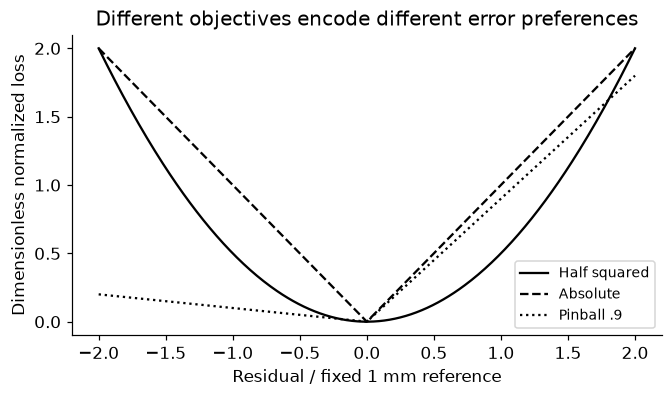

In [2]:
def pinball(y,q,tau):
 residual=np.asarray(y)-np.asarray(q)
 return np.maximum(tau*residual,(tau-1)*residual)
r=np.linspace(-2,2,401);fig,ax=plt.subplots(figsize=(6,3.5))
ax.plot(r,.5*r*r,'k-',label='Half squared');ax.plot(r,abs(r),'k--',label='Absolute');ax.plot(r,pinball(r,np.zeros_like(r),.9),'k:',label='Pinball .9')
ax.set(xlabel='Residual / fixed 1 mm reference',ylabel='Dimensionless normalized loss',title='Different objectives encode different error preferences');ax.legend(fontsize=9);plt.show()
assert np.isclose(pinball(1.,0.,.9),.9) and np.isclose(pinball(-1.,0.,.9),.1)


<a id="contract"></a>
## Fixed training controls and information boundary

Generate 900 independent members, then allocate 540/180/180 training/development/final. Fit a mean line by least squares and median/.9 lines using `QuantileRegressor(quantile=..., alpha=0, solver='highs')`. The quantile controls output meaning; alpha=0 deliberately omits the estimator's coefficient penalty; the solver is a numerical choice. The binary model is `LogisticRegression(C=1, solver='lbfgs', max_iter=1000)`, a fixed regularized logistic fit. These settings are disclosed, not claimed exhaustive API coverage. No preprocessing fit uses assessment rows.

**Predict:** can a valid sigmoid range establish probability calibration? Does a .9 quantile value have probability units?


In [3]:
from sklearn.linear_model import QuantileRegressor,LogisticRegression
N=900;x=rng.uniform(0,1,N);X=x[:,None];y=.3+1.2*x+rng.exponential(.25,N)-.25
true_p=special.expit(-1+2*x);binary=rng.binomial(1,true_p)
order=rng.permutation(N);train=order[:540];development=order[540:720];final=order[720:]
assert not set(train)&set(development) and not set(train)&set(final) and not set(development)&set(final)
A=np.column_stack([x,np.ones(N)]);mean_theta=np.linalg.lstsq(A[train],y[train],rcond=None)[0]
median_model=QuantileRegressor(quantile=.5,alpha=0,solver='highs').fit(X[train],y[train])
quantile_model=QuantileRegressor(quantile=.9,alpha=0,solver='highs').fit(X[train],y[train])
probability_model=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000).fit(X[train],binary[train])
assert mean_theta.shape==(2,) and quantile_model.quantile==.9 and probability_model.n_iter_[0]<1000
print('Fixed estimator controls recorded before final outputs; no tuning on development/final.')


Fixed estimator controls recorded before final outputs; no tuning on development/final.


<a id="output-links"></a>
## Inspect outputs and stable probability loss

For finite mathematical logits, sigmoid lies in (0,1), but floating computations can round endpoints. Binary loss `logaddexp(0,z)-y*z` avoids a direct exp/log of those endpoints. This score-space identity is checked at moderate scores and for finite loss at extreme scores. The correct target must be binary; probability prediction is separate from a cost/capacity decision.

**Predict:** what happens if a raw score of 10 is read as a probability? Which target is very costly under a large positive score?


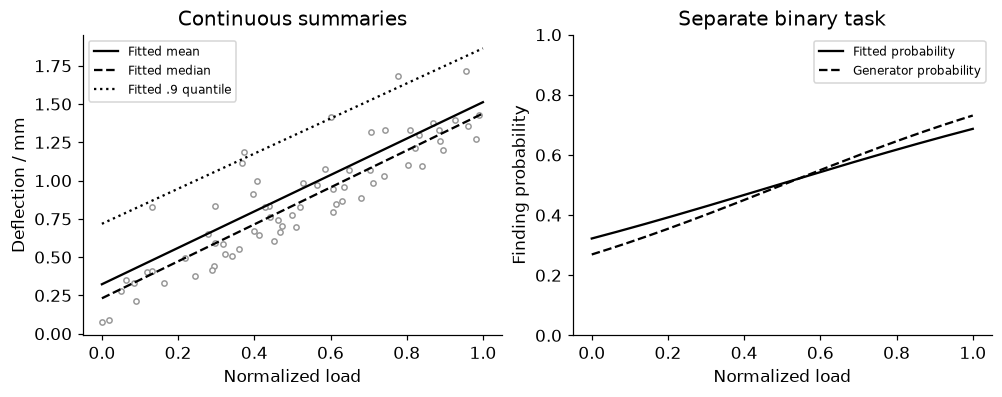

In [4]:
z=np.array([-1000.,-20.,0.,20.,1000.]);labels=np.array([1.,1.,0.,0.,0.])
stable_loss=np.logaddexp(0,z)-labels*z
assert np.isfinite(stable_loss).all() and np.all(stable_loss>=0)
moderate=np.array([-2.,0.,2.]);label=np.array([0.,1.,1.]);p=special.expit(moderate)
assert np.allclose(np.logaddexp(0,moderate)-label*moderate,-label*np.log(p)-(1-label)*np.log1p(-p))
line=np.linspace(0,1,180);lineX=line[:,None]
fig,axes=plt.subplots(1,2,figsize=(9,3.5));axes[0].scatter(x[train][::8],y[train][::8],s=12,facecolors='white',edgecolors='.6')
for pred,style,text in [(np.column_stack([line,np.ones(len(line))])@mean_theta,'-','Fitted mean'),(median_model.predict(lineX),'--','Fitted median'),(quantile_model.predict(lineX),':','Fitted .9 quantile')]:axes[0].plot(line,pred,color='black',ls=style,label=text)
axes[0].set(xlabel='Normalized load',ylabel='Deflection / mm',title='Continuous summaries');axes[0].legend(fontsize=8)
axes[1].plot(line,probability_model.predict_proba(lineX)[:,1],'k-',label='Fitted probability');axes[1].plot(line,special.expit(-1+2*line),'k--',label='Generator probability')
axes[1].set(xlabel='Normalized load',ylabel='Finding probability',ylim=(0,1),title='Separate binary task');axes[1].legend(fontsize=8);plt.show()
RESULTS['extreme_logit_losses']=stable_loss.tolist()


<a id="assessment"></a>
## Final output-specific diagnostics

All model settings and objective interpretations are now fixed. Squared/absolute/pinball losses and binary log loss measure different quantities and should not be numerically ranked across units. Empirical .9 coverage is a sample proportion, not proof of conditional coverage for every subgroup. These synthetic final outcomes are not reused to select a better model.


In [5]:
mean_prediction=A[final]@mean_theta;median_prediction=median_model.predict(X[final]);q_prediction=quantile_model.predict(X[final])
prob=probability_model.predict_proba(X[final])[:,1];logits=probability_model.decision_function(X[final])
metrics={'mean_MSE_mm2':float(np.mean((y[final]-mean_prediction)**2)),
'median_MAE_mm':float(np.mean(abs(y[final]-median_prediction))),
'quantile_pinball_mm':float(np.mean(pinball(y[final],q_prediction,.9))),
'quantile_empirical_coverage':float(np.mean(y[final]<=q_prediction)),
'binary_log_loss':float(np.mean(np.logaddexp(0,logits)-binary[final]*logits))}
assert np.all((prob>=0)&(prob<=1)) and q_prediction.shape==(180,) and all(np.isfinite(list(metrics.values())))
print(metrics);RESULTS.update(metrics)


{'mean_MSE_mm2': 0.0441701211421892, 'median_MAE_mm': 0.1528755015044243, 'quantile_pinball_mm': 0.04954681189242648, 'quantile_empirical_coverage': 0.9444444444444444, 'binary_log_loss': 0.6506375341866609}


<a id="exercises"></a>
## Exercises and hints

1. Derive the true mean, median and .9 quantile of the shifted exponential response before comparing fitted lines.
2. Change quantile level with development-only experiments and reserve new final data for a selected rule.
3. Compare a cost threshold with a probability output without retraining the model; state the cost assumptions.
4. Add a weighted physical/boundary penalty and record its unweighted residual, units and finite weight. Do not claim an exact constraint from a soft penalty.
5. Reweight positive labels and investigate what conditional distribution the weighted log loss targets. Reassess calibration before calling it a population probability.
6. Fit a noise scale under a Gaussian likelihood; include its log-normalization term and explain why squared residual alone is insufficient.

**Hints:** squared error favors a conditional mean, absolute error a median, and pinball a quantile; a probability is not a hard label. Link/range validity is necessary but insufficient for calibration. Loss, assessment metric and decision utility have distinct roles.

**Troubleshooting:** align case IDs/shapes, avoid direct log of rounded sigmoid endpoints, and distinguish mm losses from dimensionless binary loss. Official [QuantileRegressor](https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.QuantileRegressor.html) and [logistic regression](https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.LogisticRegression.html) docs define the fixed controls; the executed patch version is printed above.


In [6]:
summary={'example_id':'code_018','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['squared absolute and pinball output meanings', 'mean median and quantile fit', 'sigmoid and Bernoulli cross entropy', 'stable score-space loss', 'declared split and estimator controls', 'held-out output assessment'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["squared absolute and pinball output meanings", "mean median and quantile fit", "sigmoid and Bernoulli cross entropy", "stable score-space loss", "declared split and estimator controls", "held-out output assessment"], "elapsed_seconds": 0.439, "example_id": "code_018", "hardware": "Darwin arm64 CPU", "results": {"binary_log_loss": 0.6506375341866609, "extreme_logit_losses": [1000.0, 20.000000002061153, 0.6931471805599453, 20.000000002061153, 1000.0], "mean_MSE_mm2": 0.0441701211421892, "median_MAE_mm": 0.1528755015044243, "quantile_empirical_coverage": 0.9444444444444444, "quantile_pinball_mm": 0.04954681189242648}, "seed": 418, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
